Atividade 7

In [88]:
import pandas as pd
import matplotlib.pyplot as plt

df_customers = pd.read_csv('customers-10000.csv')

Parte 1: Análise Exploratória

1. A Região Mais Vendida:

In [60]:
clientes = df_customers.groupby(['Country','City']).size()
print(f'Cidade com maior numero de vendas: {clientes.idxmax()}')
print(f'Quantidade de vendas: {clientes.max()}')
paises = df_customers['Country'].value_counts()
print(f'País com maior venda: {paises.index[0]}')
print(f'Quantidade de vendas: {paises.iloc[0]}')


Cidade com maior numero de vendas: ('Bolivia', 'Tracifort')
Quantidade de vendas: 2
País com maior venda: Korea
Quantidade de vendas: 84


2.Datas de Maior Venda:

Subscription Date
1    1060
2     931
3    1076
4     989
5     978


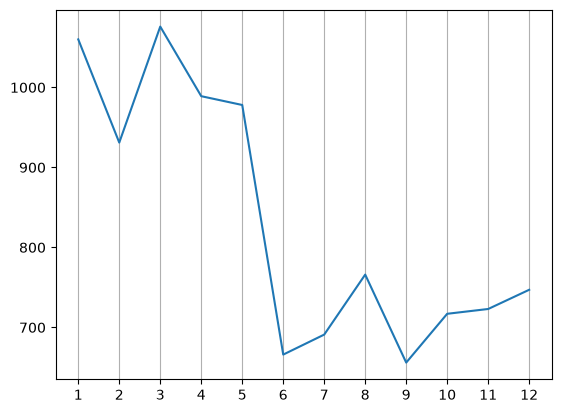

In [120]:
df_customers['Subscription Date'] = pd.to_datetime(df_customers['Subscription Date'],format='%Y-%m-%d')
mes = df_customers['Subscription Date'].dt.month.value_counts().sort_index()
print(mes.head().to_string())

grafico = plt.plot(mes.index, mes.values)
plt.xticks(range(1,13))
plt.grid(axis='x')

plt.show()


3.O Maior Cliente (B2B):

Empresa_Principal
Mack       24
Cortez     24
Heath      22
Pearson    20
Cochran    19


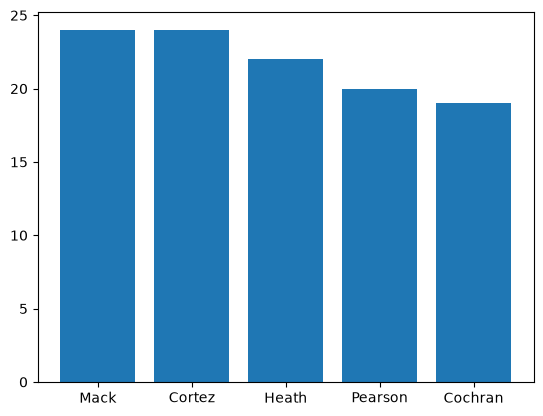

In [121]:
df_customers['Empresa_Principal'] = (df_customers['Company']
                                     .str.strip()
                                     .str.extract(r'^([A-Za-z]+)', expand=False)
                                     .str.title())

maiores_empresas = df_customers['Empresa_Principal'].value_counts().head().sort_values(ascending=False)

print(maiores_empresas.to_string())

barra = plt.bar(maiores_empresas.index, maiores_empresas.values)
